<img src="Bilder/ost_logo.png" width="240" align="right"/>
<div style="text-align: left"> <b> Machine Learning Projekt</b> <br> HS 2025 <br> <a href="mailto:ryan.mikus@ost.ch"> Ryan Mikus </a> und <a href="mailto:ilija.amato@ost.ch"> Ilija Amato </a> </div>

<h1 id="5">5. Modellierung</h1>

In diesem Abschnitt wird auf Basis der zuvor analysierten Marktdaten ein ML-basierter Modellierungsprozess für ein Pairs-Trading-Setup umgesetzt. Ziel ist es, die zukünftige Spread-Bewegung über einen festen Horizont vorherzusagen und verschiedene Modellarchitekturen unter zeitlich konsistenten Bedingungen zu vergleichen.

Der Fokus liegt auf der praktischen Umsetzung, der Vergleichbarkeit der Modelle sowie der Analyse der resultierenden Outputs. Die Evaluation erfolgt mittels Walk-Forward-Ansatz und wird durch Performance- und Diagnosemetriken ergänzt.

<img src="Bilder/ml_pipeline.png" width="240" style="display:block; margin-left:auto; margin-right:auto;"/>

Die Abbildung zeigt den Ablauf der verwendeten ML-Pipeline – von den Marktdaten über Feature-Engineering und Modellierung bis hin zur Performance- und Trading-Inspektion.

In diesem Kapitel werden folgende Schritte behandelt:

- [Projektspezifisches Preprocessing](#51)
- [Modellarchitekturen](#52)
- [Hyperparameter-Tuning](#53)
- [Walk-Forward Evaluation](#54)
- [Modellperformance und Vergleich](#56)
- [Trading-Inspektion](#57)

In [1]:
# Zelle 1: Imports & Konfiguration
import numpy as np
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, VotingClassifier
from xgboost import XGBClassifier

from pairs_trading import data_io as io
from pairs_trading import modeling


# Dateninput
DATA_DIR = "Daten"
BASENAME = "market_data_cleaned"

# Zeitraum
# Es braucht mindestens:
# LOOKBACK_PAIRS_DAYS + LOOKBACK_TRAIN_DAYS + 1
# Tage im Dataset, damit es funktioniert. Das 1 ist der Testtag.
START_DATE = "earliest"
END_DATE = "latest"

# Walk-forward Fenster (Handelstage)
LOOKBACK_PAIR_DAYS = 10      # Lookback für Pair-Selektion (Korrelation + Cointegration)
LOOKBACK_TRAIN_DAYS = 10     # Rolling Train-Window für ML-Fit

# Pair-Selektion
TOP_CORR_PAIRS = 50          # Top-N Paare nach |corr| (Candidate-Set)
TOP_DAILY_PAIRS = 5          # Top-N Paare nach Cointegration-Consistency
P_COINTEGRATION = 0.05       # p-Value Schwelle für "signifikant" pro Tag

# Rebalance / Cache
REBALANCE_EVERY_N_DAYS = 5   # Paare nur alle N Handelstage neu bestimmen
CACHE_DIR = "cache_pairs"

# Reproduzierbarkeit / Parallelisierung
RANDOM_STATE = 42
N_JOBS = -1

# Horizon k
K_FIXED = 5
best_k = K_FIXED # könnte noch optimiert werden

# Feature Parameter
RSI_W = 14
Z_W = 60
VOL_W = 20

# XGB Hyperparameter Tuning
TUNE_XGB_LR = True          # True = tuning ausführen, False = fixen Wert nutzen
XGB_LR_CANDIDATES = [0.001, 0.005, 0.01, 0.02]
XGB_LR_BEST = 0.01           # hier manuell setzen oder automatisch überschreiben

In [2]:
# Zelle 2: Gesäuberte Daten laden
df = io.load_preprocessed_data(
    data_dir="Daten",
    basename=BASENAME
)


[Preprocessed Data Load]
Pfad: Daten\market_data_cleaned.parquet

[Preprocessed Data]
Shape: (7490150, 7)
Spalten: ['datetime', 'symbol', 'open', 'high', 'low', 'volume', 'close_filled']

Head:
                   datetime symbol        open        high         low  \
0 2025-11-07 14:30:00+00:00      A  146.520004  147.119995  145.729996   
1 2025-11-07 14:31:00+00:00      A         NaN         NaN         NaN   
2 2025-11-07 14:32:00+00:00      A  146.089996  146.089996  146.089996   
3 2025-11-07 14:33:00+00:00      A         NaN         NaN         NaN   
4 2025-11-07 14:34:00+00:00      A  146.049698  146.049698  146.049698   

    volume  close_filled  
0  13361.0    145.729996  
1      NaN    145.909996  
2    427.0    146.089996  
3      NaN    146.069847  
4   1387.0    146.049698  


<h2 id="51">5.1. Projektspezifisches Preprocessing</h2>

Wie bereits erwähnt, wird für dieses Projekt nur die Spalte `close_filled` verwendet. Die Daten werden wieder in das Wide-Format transformiert und logarithmiert.

In [3]:
# Zelle 3: Unnötige Spalten droppen
df = df[["datetime", "symbol", "close_filled"]].copy()
df.head()

,datetime,symbol,close_filled
0,2025-11-07 14:30:00+00:00,A,145.729996
1,2025-11-07 14:31:00+00:00,A,145.909996
2,2025-11-07 14:32:00+00:00,A,146.089996
3,2025-11-07 14:33:00+00:00,A,146.069847
4,2025-11-07 14:34:00+00:00,A,146.049698


In [4]:
# Zelle 4: Zeitraum definieren
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")

if START_DATE == "earliest":
    start_ts = df["datetime"].min()
else:
    start_ts = pd.to_datetime(START_DATE, utc=True)

if END_DATE == "latest":
    end_ts = df["datetime"].max()
else:
    end_ts = pd.to_datetime(END_DATE, utc=True)

df = df[(df["datetime"] >= start_ts) & (df["datetime"] <= end_ts)]

print(
    "Data range after slicing:",
    df["datetime"].min(),
    "->",
    df["datetime"].max(),
)

Data range after slicing: 2025-11-07 14:30:00+00:00 -> 2026-01-09 21:00:00+00:00


In [5]:
# Zelle 5: Long -> Wide
df = df.copy()
df["datetime"] = pd.to_datetime(df["datetime"], utc=True, errors="coerce")
df = df.dropna(subset=["datetime", "symbol", "close_filled"]).sort_values(["datetime", "symbol"])

prices_wide = (
    df.pivot(index="datetime", columns="symbol", values="close_filled")
    .sort_index()
)

print("prices_wide shape:", prices_wide.shape)
print("date range:", prices_wide.index.min(), "->", prices_wide.index.max())

prices_wide shape: (15638, 479)
date range: 2025-11-07 14:30:00+00:00 -> 2026-01-09 21:00:00+00:00


Für die nachfolgenden Schritte (Pair-Selektion, Feature-Berechnung und Walk-Forward) wird das Wide-Format als zweckmäßige Arbeitsrepräsentation verwendet, auch wenn es nicht dem Tidy-Data-Prinzip entspricht.

In [6]:
# Zelle 6: Log-Preise (Input für Cointegration/Features)
log_prices = np.log(prices_wide).dropna(how="all")
print("log_prices shape:", log_prices.shape)

log_prices shape: (15638, 479)


In [7]:
# Zelle 7: Handelstage & Walk-forward Setup
all_days = pd.Index(log_prices.index.normalize().unique()).sort_values()
print("n_days:", len(all_days), "| first:", all_days.min().date(), "| last:", all_days.max().date())

min_required = max(LOOKBACK_PAIR_DAYS, LOOKBACK_TRAIN_DAYS)
test_days = all_days[min_required:]
print("walk-forward test days:", len(test_days))

n_days: 40 | first: 2025-11-07 | last: 2026-01-09
walk-forward test days: 30


<h2 id="52">5.2. Modellarchitekturen</h2>

Zur Vorhersage der Spread-Bewegung werden mehrere Machine-Learning-Modelle mit unterschiedlicher Modellkomplexität eingesetzt. Ziel ist ein robuster Vergleich linearer, baumbasierter und ensemblebasierter Ansätze unter identischen Daten- und Evaluationsbedingungen.

Neben einer logistischen Regression als lineare Baseline kommen ein Random-Forest-Classifier sowie ein Gradient-Boosting-Modell (XGBoost) zum Einsatz. Ergänzend wird ein Soft-Voting-Ensemble verwendet, das die probabilistischen Outputs aller Einzelmodelle kombiniert, um Stabilität und Robustheit der Vorhersagen zu erhöhen.

Alle Modelle werden in einer einheitlichen Pipeline definiert und ausschließlich im Rahmen des Walk-Forward-Prozesses trainiert und evaluiert, um zeitliches Leckage zu vermeiden und eine realistische Performanceabschätzung zu gewährleisten.

In [8]:
# Zelle 8: Modelle definieren
logreg = Pipeline([
    ("clf", LogisticRegression(
        max_iter=2000,
        solver="lbfgs",
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
    ))
])

rf = Pipeline([
    ("clf", RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_leaf=10,
        n_jobs=N_JOBS,
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample",
    ))
])

xgb = Pipeline([
    ("clf", XGBClassifier(
        n_estimators=400,
        learning_rate=0.05,
        max_depth=4,
        subsample=0.8,
        colsample_bytree=0.8,
        reg_lambda=1.0,
        random_state=RANDOM_STATE,
        n_jobs=0,            # xgboost erwartet int; 0 = alle Threads
        eval_metric="logloss",
        tree_method="hist",
    ))
])

vote_soft = VotingClassifier(
    estimators=[
        ("lr", clone(logreg)),
        ("rf", clone(rf)),
        ("xgb", clone(xgb)),
    ],
    voting="soft",
    n_jobs=N_JOBS,
)

models = {
    "LogReg": logreg,
    "RF": rf,
    "XGB": xgb,
    "VoteSoft": vote_soft,
}

<h2 id="53">5.3. Hyperparameter-Tuning</h2>

Zur Begrenzung der Rechenkomplexität wird das Hyperparameter-Tuning gezielt auf die Lernrate des XGBoost-Modells beschränkt. Diese Entscheidung erlaubt einen kontrollierten Vergleich, ohne den Walk-Forward-Prozess durch umfangreiche Grid- oder Random-Search-Verfahren zu verzerren.

Die Bewertung erfolgt mittels walk-forward-basierter Evaluation auf Basis der mittleren AUC über alle Testtage. Der Hyperparameter mit der besten durchschnittlichen Performance wird anschließend fixiert und im finalen Modellvergleich verwendet.

In [9]:
# Zelle 9: Hyperparameter-Tuning (XGB learning_rate)
if TUNE_XGB_LR:
    print("Tuning XGB learning_rate...")

    lr_results = []

    for lr in XGB_LR_CANDIDATES:
        print(f"   testing learning_rate = {lr}")

        # Modell mit neuer LR setzen
        models["XGB"].named_steps["clf"].set_params(learning_rate=lr)

        scores = modeling.walk_forward_run(
            k=best_k,
            models={"XGB": models["XGB"]},
            log_prices=log_prices,
            all_days=all_days,
            test_days=test_days,
            lookback_train_days=LOOKBACK_TRAIN_DAYS,
            lookback_pair_days=LOOKBACK_PAIR_DAYS,
            top_corr_pairs=TOP_CORR_PAIRS,
            top_daily_pairs=TOP_DAILY_PAIRS,
            p_cointegration=P_COINTEGRATION,
            rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
            cache_dir=CACHE_DIR,
            rsi_w=RSI_W,
            z_w=Z_W,
            vol_w=VOL_W,
            min_train_samples=200,
            min_test_samples=50,
            verbose=False,
        )

        mean_auc = scores["auc"].mean()
        lr_results.append((lr, mean_auc))

        print(f"      mean AUC = {mean_auc:.4f}")

    # best LR bestimmen
    XGB_LR_BEST, best_auc = max(lr_results, key=lambda x: x[1])

    print(f"\nBest learning_rate = {XGB_LR_BEST} (mean AUC = {best_auc:.4f})")

# finalen Wert setzen (immer!)
models["XGB"].named_steps["clf"].set_params(learning_rate=XGB_LR_BEST)

Tuning XGB learning_rate...
   testing learning_rate = 0.001
      mean AUC = 0.7359
   testing learning_rate = 0.005
      mean AUC = 0.7388
   testing learning_rate = 0.01
      mean AUC = 0.7396
   testing learning_rate = 0.02
      mean AUC = 0.7383

Best learning_rate = 0.01 (mean AUC = 0.7396)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.8, device=None, early_stopping_rounds=None,
              enable_categorical=False, eval_metric='logloss',
              feature_types=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.01, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=4,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=400,
              n_jobs=0, num_parallel_tree=None, random_state=42, ...)

<h2 id="54">5.4. Walk-Forward Evaluation</h2>

Die Modellbewertung erfolgt mittels eines rollierenden Walk-Forward-Ansatzes, bei dem für jeden Handelstag ein neues Modell auf einem festen historischen Fenster trainiert und auf dem unmittelbar folgenden Testzeitpunkt evaluiert wird. Dieses Vorgehen stellt eine strikt zeitlich konsistente Evaluation sicher und vermeidet Informationsleckagen.

Als primäre Bewertungsmetrik wird die Area Under the ROC Curve (AUC) verwendet, da sie unabhängig von einem festen Klassifikationsschwellenwert ist und die Trennschärfe der Modelle über alle Entscheidungsgrenzen hinweg abbildet. Dies ist insbesondere für probabilistische Handelssignale vorteilhaft, bei denen der finale Schwellenwert erst in einem späteren Schritt festgelegt wird.

Die Modellierung erfolgt als binäres Klassifikationsproblem. Die Zielvariable beschreibt, ob sich der Spread über den Prognosehorizont \(k\) in die erwartete Richtung bewegt (Label = 1) oder nicht (Label = 0). Die Modelle liefern entsprechend probabilistische Vorhersagen für das Eintreten der positiven Klasse.

In [ ]:
# Zelle 10: Walk-forward Run
final_scores = modeling.walk_forward_run(
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
    verbose=True,
)

display(final_scores.head())

final_summary = (
    final_scores.groupby("model")["auc"]
    .agg(["mean", "std"])
    .sort_values("mean", ascending=False)
)
display(final_summary)

2025-11-21 | best_auc=0.725
2025-11-24 | best_auc=0.736
2025-11-25 | best_auc=0.727
2025-11-26 | best_auc=0.763
2025-12-01 | best_auc=0.721
2025-12-02 | best_auc=0.723
2025-12-03 | best_auc=0.726
2025-12-04 | best_auc=0.751
2025-12-05 | best_auc=0.715
2025-12-08 | best_auc=0.719
2025-12-09 | best_auc=0.727
2025-12-10 | best_auc=0.746
2025-12-11 | best_auc=0.734
2025-12-12 | best_auc=0.724
2025-12-15 | best_auc=0.737
2025-12-16 | best_auc=0.730
2025-12-17 | best_auc=0.739
2025-12-18 | best_auc=0.750
2025-12-19 | best_auc=0.743
2025-12-22 | best_auc=0.744
2025-12-23 | best_auc=0.774
2025-12-26 | best_auc=0.753
2025-12-29 | best_auc=0.760
2025-12-30 | best_auc=0.738
2025-12-31 | best_auc=0.775
2026-01-02 | best_auc=0.742
2026-01-05 | best_auc=0.744
2026-01-07 | best_auc=0.739
2026-01-08 | best_auc=0.741
2026-01-09 | best_auc=0.742


,day,model,auc,n_pairs,n_train,n_test
0,2025-11-21 00:00:00+00:00,LogReg,0.547224,5,19255,1660
1,2025-11-21 00:00:00+00:00,RF,0.715162,5,19255,1660
2,2025-11-21 00:00:00+00:00,XGB,0.725231,5,19255,1660
3,2025-11-21 00:00:00+00:00,VoteSoft,0.721145,5,19255,1660
4,2025-11-24 00:00:00+00:00,LogReg,0.490067,5,19255,1660


,mean,std,count
model,,,
XGB,0.739618,0.015209,30
VoteSoft,0.733158,0.014199,30
RF,0.727994,0.013887,30
LogReg,0.500435,0.030210,30


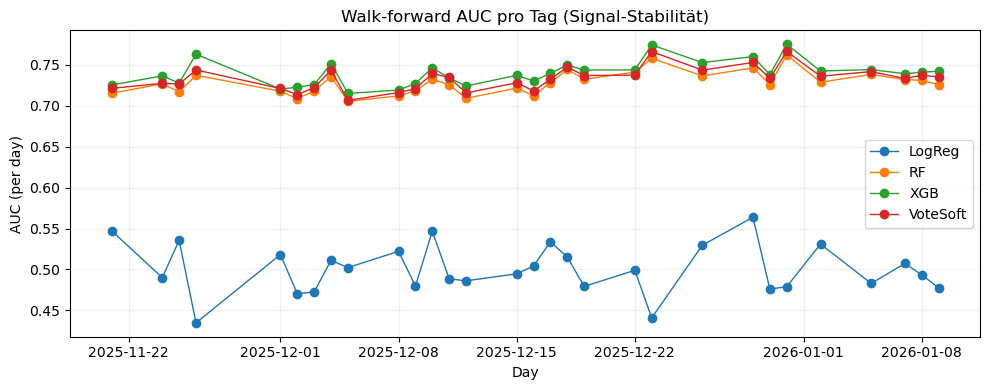

In [11]:
# Zelle 11: AUC pro Tag (Signal-Stabilität)
modeling.plot_auc_per_day(final_scores)

Die aggregierten AUC-Ergebnisse zeigen, dass nichtlineare und ensemblebasierte Modelle die lineare Baseline deutlich übertreffen. XGBoost erzielt die höchste durchschnittliche AUC bei geringer Varianz über die Walk-Forward-Perioden und wird daher in den folgenden Analysen als Referenzmodell verwendet. Die AUC-Verläufe über die Zeit weisen insgesamt auf eine robuste, tagesübergreifend stabile Modellgüte hin.

<h2 id="55">5.5. Modellperformance</h2>

In diesem Abschnitt wird die Performance der Modelle anhand aggregierter Metriken sowie diagnostischer Visualisierungen analysiert. Neben der durchschnittlichen Vorhersagegüte werden insbesondere Stabilität, Robustheit und Entscheidungscharakteristika der Modelle betrachtet.

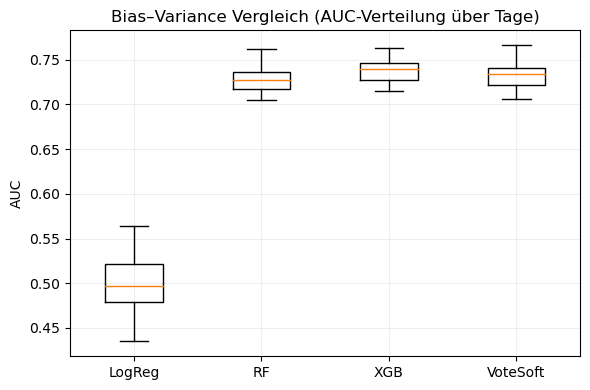

In [12]:
# Zelle 12: Bias–Variance Vergleich (AUC-Verteilung)
modeling.plot_auc_boxplot(final_scores)

Der Bias–Variance-Vergleich zeigt, dass die logistische Regression eine deutlich geringere Trennschärfe und höhere Varianz aufweist. Die baumbasierten Modelle liefern konsistent höhere AUC-Werte, wobei XGBoost und das Soft-Voting-Ensemble sowohl eine hohe Median-Performance als auch eine geringe Streuung über die Tage zeigen.

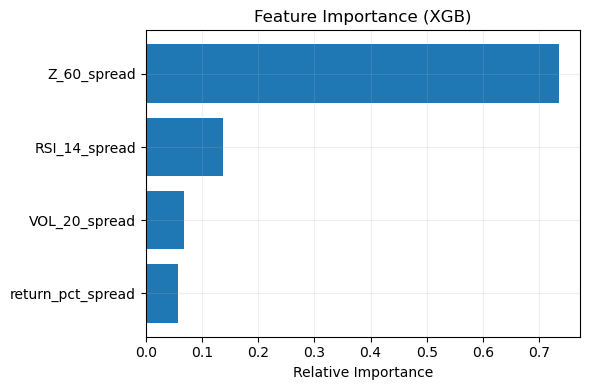

,feature,importance
0,return_pct_spread,0.058211
1,VOL_20_spread,0.068004
2,RSI_14_spread,0.137837
3,Z_60_spread,0.735947


In [13]:
# Zelle 13: Feature Importance (XGB)
xgb_clf = models["XGB"].named_steps["clf"]

feature_names = [
    f"RSI_{RSI_W}_spread",
    f"Z_{Z_W}_spread",
    f"VOL_{VOL_W}_spread",
    "return_pct_spread",
]

imp_df = modeling.plot_xgb_feature_importance(
    feature_importances=xgb_clf.feature_importances_,
    feature_names=feature_names,
)
display(imp_df)

Die Feature-Importance-Analyse des XGBoost-Modells zeigt, dass der Z-Score des Spreads den dominierenden Einfluss auf die Modellentscheidung besitzt. Technische Indikatoren wie RSI und Volatilität liefern ergänzende Informationen, während kurzfristige Renditeänderungen eine untergeordnete Rolle spielen.

Im Vergleich zu einer früheren Konfiguration ohne Learning-Rate-Tuning verschob sich die Gewichtung stärker in Richtung Z-Score, was auf eine veränderte Modellnutzung der Feature-Signale durch die optimierte Parametrisierung hinweist.

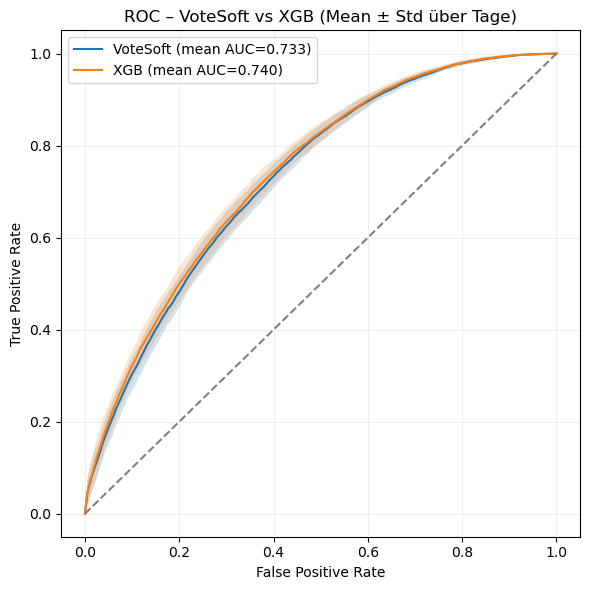

In [14]:
# Zelle 14: ROC – VoteSoft vs XGB
roc_vote = modeling.roc_mean_std_band(
    model_name="VoteSoft",
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

roc_xgb = modeling.roc_mean_std_band(
    model_name="XGB",
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

modeling.plot_roc_mean_std_comparison(
    roc_a=roc_vote,
    roc_b=roc_xgb,
    label_a="VoteSoft",
    label_b="XGB",
    title="ROC – VoteSoft vs XGB (Mean ± Std über Tage)",
)

Die gemittelten ROC-Kurven zeigen für beide Modelle eine hohe und stabile Trennschärfe über alle Schwellenwerte hinweg. XGBoost erreicht dabei eine leicht höhere durchschnittliche AUC, während das Voting-Ensemble eine vergleichbare, konsistente Performance liefert.

Hier ist zu bemerken, dass XGBoost vor dem Hyperparameter-Boosting eine leicht tiefere durchschnittliche AUC lieferte (im Vergleich zum Voting-Ensemble).

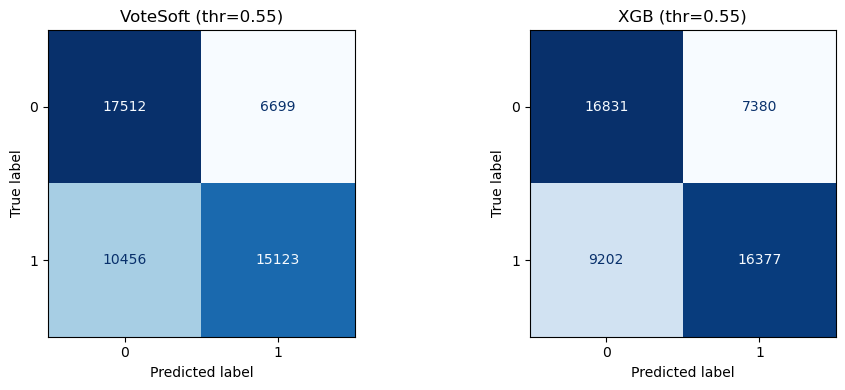

In [15]:
# Zelle 15: Confusion Matrix – VoteSoft vs XGB (gleicher Threshold)
threshold = 0.55

cm_vote = modeling.confusion_for_model(
    model_name="VoteSoft",
    k=best_k,
    threshold=threshold,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

cm_xgb = modeling.confusion_for_model(
    model_name="XGB",
    k=best_k,
    threshold=threshold,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

modeling.plot_confusion_matrices_side_by_side(
    cm_left=cm_vote,
    cm_right=cm_xgb,
    title_left=f"VoteSoft (thr={threshold})",
    title_right=f"XGB (thr={threshold})",
)

Bei identischem Entscheidungsschwellenwert zeigt XGBoost eine höhere Sensitivität für positive Klassen, während das Voting-Ensemble konservativer agiert. Diese Unterschiede verdeutlichen die unterschiedliche Charakteristik der Modelle bei der finalen Klassifikationsentscheidung.

<h2 id="56">5.6. Trading-Inspektion</h2>

In diesem Abschnitt wird das Modellverhalten aus einer tradingnahen Perspektive untersucht. Ziel ist keine Performance-Optimierung oder Strategieentwicklung, sondern eine Plausibilitätsprüfung der modellbasierten Signale anhand aggregierter PnL- und Risikoindikatoren.

Die Trading-Inspektion ist ausdrücklich kein vollständiger Backtest: es fehlen u. a. Slippage, Positionsgrößen-/Kapitalmodellierung, Portfolioaggregation sowie ein konsistentes Risiko- und Execution-Setup.

,day,pnl,n_trades,hit_rate,equity,drawdown
0,2025-11-21 00:00:00+00:00,-42.358832,803,0.450765,-42.358832,0.000000
1,2025-11-24 00:00:00+00:00,-62.091554,798,0.430581,-104.450386,-62.091554
2,2025-11-25 00:00:00+00:00,-48.492999,850,0.451376,-152.943385,-110.584553
3,2025-11-26 00:00:00+00:00,-87.767144,716,0.445872,-240.710529,-198.351697
4,2025-12-01 00:00:00+00:00,-59.133702,733,0.436697,-299.844231,-257.485399


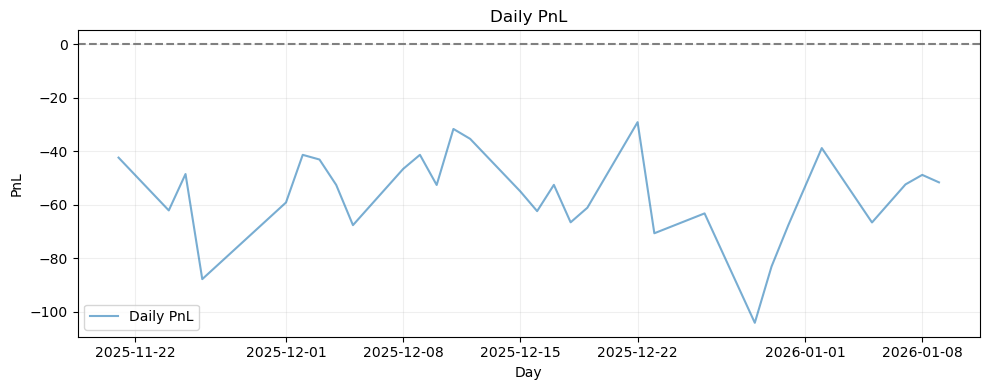

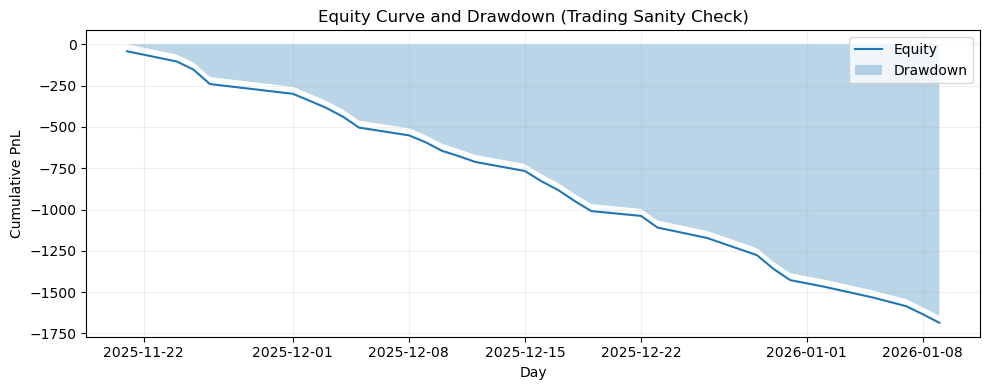

In [16]:
# Zelle 16: Trading-Inspektion – Daily PnL (kein Backtest)
MODEL_FOR_TRADING = "XGB"
THRESHOLD = 0.55
TCOST_BP = 0

trade_df = modeling.walk_forward_collect_trading_artifacts(
    model_name=MODEL_FOR_TRADING,
    k=best_k,
    models=models,
    log_prices=log_prices,
    all_days=all_days,
    test_days=test_days,
    lookback_train_days=LOOKBACK_TRAIN_DAYS,
    lookback_pair_days=LOOKBACK_PAIR_DAYS,
    top_corr_pairs=TOP_CORR_PAIRS,
    top_daily_pairs=TOP_DAILY_PAIRS,
    p_cointegration=P_COINTEGRATION,
    rebalance_every_n_days=REBALANCE_EVERY_N_DAYS,
    cache_dir=CACHE_DIR,
    rsi_w=RSI_W,
    z_w=Z_W,
    vol_w=VOL_W,
    min_train_samples=200,
    min_test_samples=50,
)

trades = trade_df.copy()

trades["enter"] = trades["proba"] > THRESHOLD
trades["direction"] = np.where(trades["z"] > 0, -1, 1)

trades["gross_pnl"] = trades["direction"] * trades["spread_ret_k"]
trades["cost"] = TCOST_BP / 1e4
trades["net_pnl"] = np.where(
    trades["enter"],
    trades["gross_pnl"] - trades["cost"],
    0.0,
)

daily = (
    trades.groupby("day")
    .agg(
        pnl=("net_pnl", "sum"),
        n_trades=("enter", "sum"),
        hit_rate=("gross_pnl", lambda x: (x > 0).mean()),
    )
    .reset_index()
)

daily["equity"] = daily["pnl"].cumsum()
daily["drawdown"] = daily["equity"] - daily["equity"].cummax()

display(daily.head())

modeling.plot_daily_pnl(daily)

modeling.plot_equity_and_drawdown(daily)

Der dargestellte PnL sowie die Equity-Kurve sind in relativen Spread-Erträgen angegeben und dienen ausschließlich der qualitativen Beurteilung des Modellverhaltens. Es handelt sich nicht um monetäre Gewinne oder Verluste.

Die Equity-Kurve weist einen kontinuierlichen Kapitalrückgang sowie einen zunehmenden Drawdown auf. Dies verdeutlicht, dass selbst ein Modell mit überdurchschnittlicher AUC nicht zwangsläufig zu einer profitablen Handelsstrategie führt, insbesondere wenn Entscheidungsregeln, Positionsgrößen und Risikobegrenzungen stark vereinfacht sind.

Der Vergleich zwischen Modellperformance und Trading-Inspektion zeigt, dass eine hohe Vorhersagegüte (AUC) nicht direkt in positive Handelsergebnisse übersetzt werden kann. Während die Modelle in der Lage sind, statistische Muster im Spread zu erkennen, erfordert profitables Trading zusätzliche Komponenten wie eine explizite Positionslogik, ein abgestimmtes Threshold-Management, Transaktionskosten sowie ein konsistentes Risikomanagement.

---

<div style="display: flex; justify-content: space-between; margin-top: 30px;">
  <a href="04_Explorative_Datenanalyse.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Zurück
    </button>
  </a>
  <a href="06_Fazit.ipynb">
    <button style="background-color:#007acc;color:white;border:none;padding:8px 12px;border-radius:6px;cursor:pointer;">
      Weiter
    </button>
  </a>
</div>
